# 📈 Stock Price Prediction using Linear Regression
**Dataset:** 200 companies × 12 months (`stock_data.csv`)  
**Goal:** Predict a company's monthly **Close price** from its trading and fundamental data.

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 5)


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.11/site-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 701, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.11/site-p

AttributeError: _ARRAY_API not found

## 2. Import the Data

In [4]:
df = pd.read_csv('data.csv', parse_dates=['Date'])
print('Shape:', df.shape)
df.head()

Shape: (2400, 14)


,Ticker,Company,Sector,Date,Open,High,Low,Close,Volume,EPS,PE_Ratio,Market_Cap_Mn,Revenue_Growth_Pct,Debt_to_Equity
0,AM000,Alpha Motors,Automobile,2025-11-01,370.11,407.20,366.48,402.79,2212232,10.74,37.50,263133.77,-0.95,0.12
1,AM000,Alpha Motors,Automobile,2025-12-01,402.79,403.36,363.85,373.70,1869305,10.53,35.48,244128.16,5.92,0.09
2,AM000,Alpha Motors,Automobile,2026-01-01,373.70,443.40,367.13,424.89,8296782,10.56,40.24,277565.31,0.56,0.09
3,AM000,Alpha Motors,Automobile,2026-02-01,424.89,429.84,412.18,414.88,1359455,10.59,39.19,271030.90,-0.86,0.13
4,AM000,Alpha Motors,Automobile,2026-03-01,414.88,416.33,401.07,404.44,2534786,10.79,37.48,264209.30,2.57,0.16


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Ticker              2400 non-null   str           
 1   Company             2400 non-null   str           
 2   Sector              2400 non-null   str           
 3   Date                2400 non-null   datetime64[us]
 4   Open                2400 non-null   float64       
 5   High                2400 non-null   float64       
 6   Low                 2400 non-null   float64       
 7   Close               2400 non-null   float64       
 8   Volume              2400 non-null   int64         
 9   EPS                 2400 non-null   float64       
 10  PE_Ratio            2400 non-null   float64       
 11  Market_Cap_Mn       2400 non-null   float64       
 12  Revenue_Growth_Pct  2400 non-null   float64       
 13  Debt_to_Equity      2400 non-null   float64       
dtypes: 

In [6]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,2400,2026-04-16 16:00:00,2025-11-01 00:00:00,2026-01-24 06:00:00,2026-04-16 00:00:00,2026-07-08 18:00:00,2026-10-01 00:00:00,NaN
Open,2400.0,142.930287,7.93,63.325,103.96,172.3825,991.29,129.138915
High,2400.0,148.747208,8.34,65.3975,107.535,178.475,1021.76,134.664544
Low,2400.0,138.585962,7.8,61.155,101.11,166.7025,953.66,125.489575
Close,2400.0,144.242263,7.93,63.45,104.175,173.2225,991.29,130.865141
Volume,2400.0,2995063.690833,629519.0,1983314.5,2674731.0,3673174.0,12838469.0,1462640.978149
EPS,2400.0,6.958917,0.33,2.6675,4.81,8.85,43.62,6.354404
PE_Ratio,2400.0,23.205796,7.05,16.4775,22.935,29.4,66.74,8.66234
Market_Cap_Mn,2400.0,64589.501004,923.48,21405.78,39130.565,69799.3775,508245.91,74454.510844
Revenue_Growth_Pct,2400.0,0.83695,-10.17,-1.25,0.87,2.97,12.22,3.180894


## 3. Data Cleaning
Checking for missing values, duplicates, wrong values and outliers.

In [7]:
print('Missing values:\n', df.isnull().sum(), sep='')
print('\nDuplicate rows:', df.duplicated().sum())
print('Companies:', df['Company'].nunique(), '| Months:', df['Date'].nunique())

Missing values:
Ticker                0
Company               0
Sector                0
Date                  0
Open                  0
High                  0
Low                   0
Close                 0
Volume                0
EPS                   0
PE_Ratio              0
Market_Cap_Mn         0
Revenue_Growth_Pct    0
Debt_to_Equity        0
dtype: int64

Duplicate rows: 0
Companies: 200 | Months: 12


In [8]:
# Remove duplicates & rows with missing values (none expected, but kept for safety)
df = df.drop_duplicates().dropna().reset_index(drop=True)

# Sanity checks: prices and volume must be positive, High >= Low
df = df[(df[['Open','High','Low','Close','Volume']] > 0).all(axis=1) & (df['High'] >= df['Low'])]

# Feature engineering
df['Month'] = df['Date'].dt.month
df['Monthly_Return_Pct'] = (df['Close'] - df['Open']) / df['Open'] * 100
df = df.sort_values(['Company','Date']).reset_index(drop=True)
print('Clean shape:', df.shape)

Clean shape: (2400, 16)


In [9]:
# Outlier check with IQR on Close price
q1, q3 = df['Close'].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = df[(df['Close'] > q3 + 1.5*iqr) | (df['Close'] < q1 - 1.5*iqr)]
print(f'High-price outliers: {len(outliers)} rows ({len(outliers)/len(df):.1%}) - genuine expensive stocks, so we keep them')

High-price outliers: 183 rows (7.6%) - genuine expensive stocks, so we keep them


## 4. Data Visualisations

### 4.1 Distribution of Close Price

OptionError: No such keys(s): 'mode.use_inf_as_na'

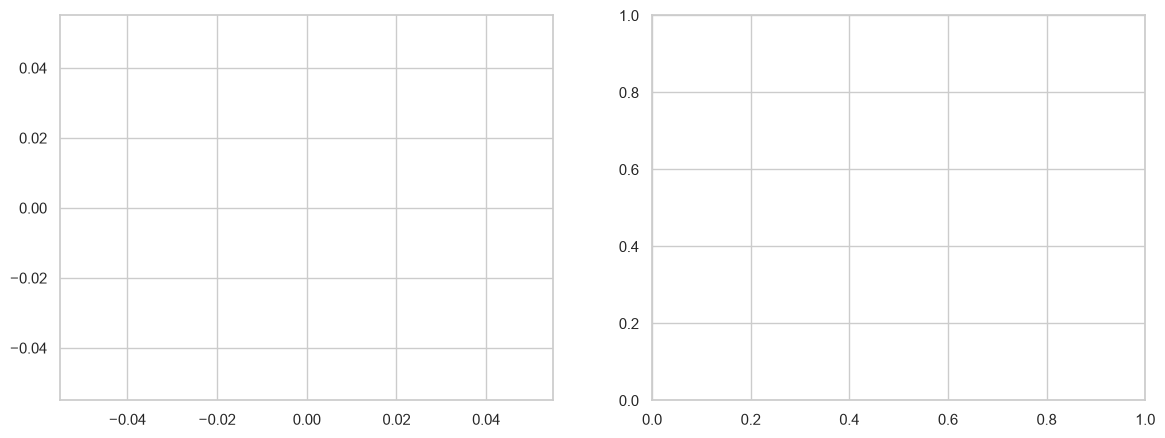

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['Close'], bins=40, kde=True, ax=ax[0])
ax[0].set_title('Close Price Distribution')
sns.histplot(np.log(df['Close']), bins=40, kde=True, color='green', ax=ax[1])
ax[1].set_title('Log of Close Price Distribution')
plt.show()

### 4.2 Average Close Price by Sector

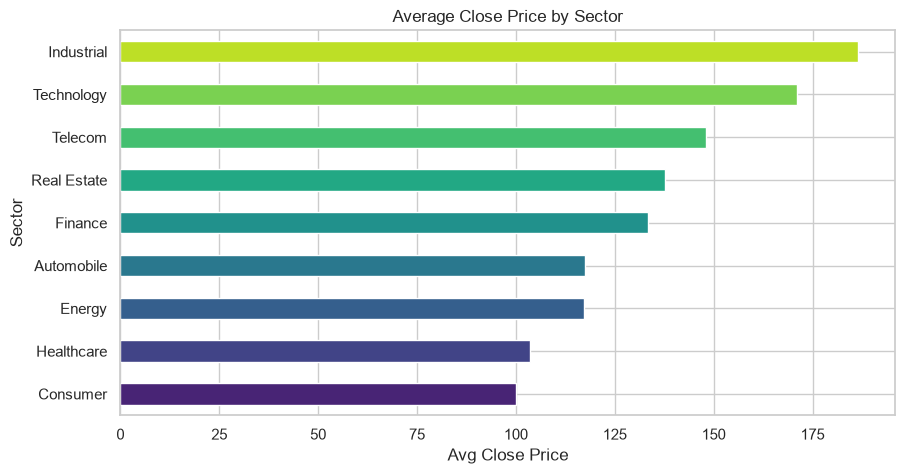

In [11]:
sector_avg = df.groupby('Sector')['Close'].mean().sort_values()
sector_avg.plot(kind='barh', color=sns.color_palette('viridis', len(sector_avg)))
plt.title('Average Close Price by Sector'); plt.xlabel('Avg Close Price')
plt.show()

### 4.3 Box Plot of Close Price by Sector

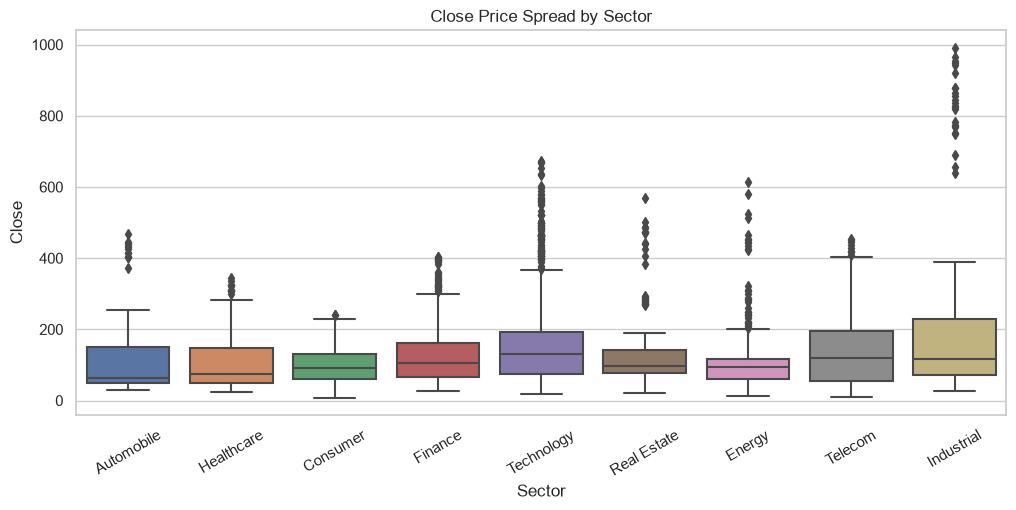

In [12]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x='Sector', y='Close')
plt.xticks(rotation=30); plt.title('Close Price Spread by Sector')
plt.show()

### 4.4 Market Trend over 12 Months

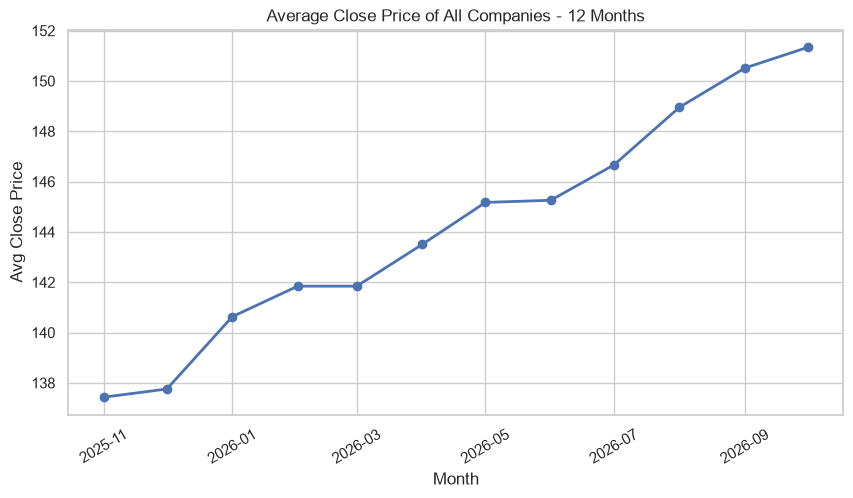

In [13]:
monthly = df.groupby('Date')['Close'].mean()
plt.plot(monthly.index, monthly.values, marker='o', linewidth=2)
plt.title('Average Close Price of All Companies - 12 Months')
plt.xlabel('Month'); plt.ylabel('Avg Close Price'); plt.xticks(rotation=30)
plt.show()

### 4.5 Sector-wise Trend

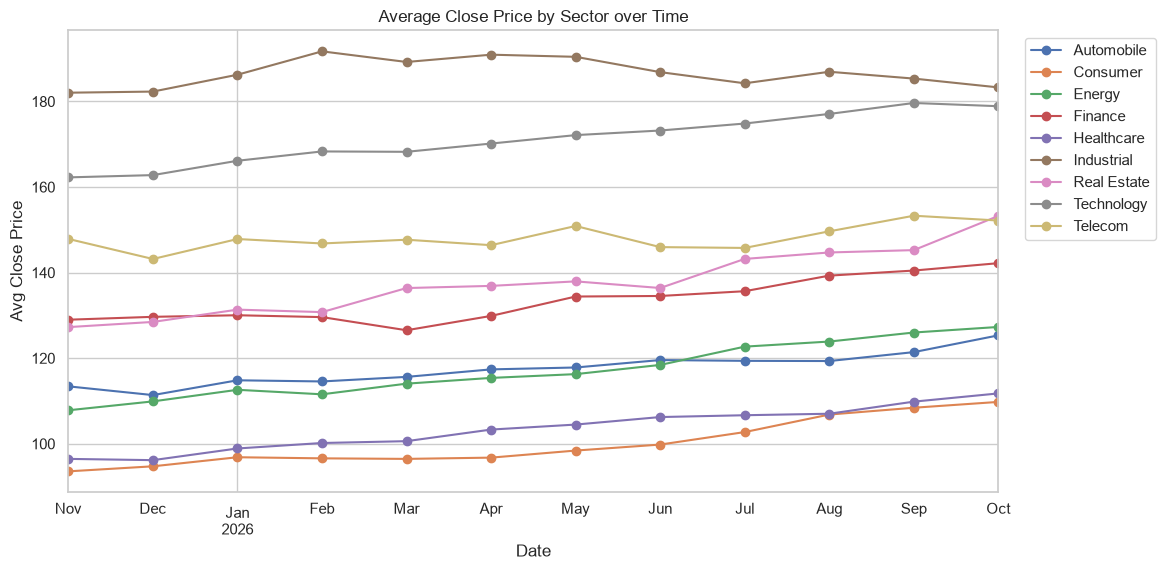

In [14]:
sector_trend = df.pivot_table(index='Date', columns='Sector', values='Close', aggfunc='mean')
sector_trend.plot(figsize=(12, 6), marker='o')
plt.title('Average Close Price by Sector over Time'); plt.ylabel('Avg Close Price')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

### 4.6 Top 10 Companies by Average Close Price

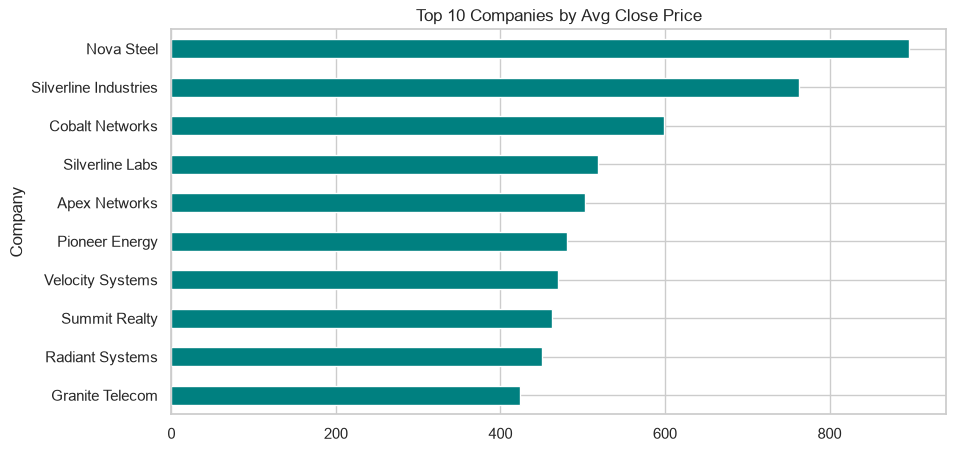

In [15]:
top10 = df.groupby('Company')['Close'].mean().nlargest(10).sort_values()
top10.plot(kind='barh', color='teal')
plt.title('Top 10 Companies by Avg Close Price')
plt.show()

### 4.7 Correlation Heatmap

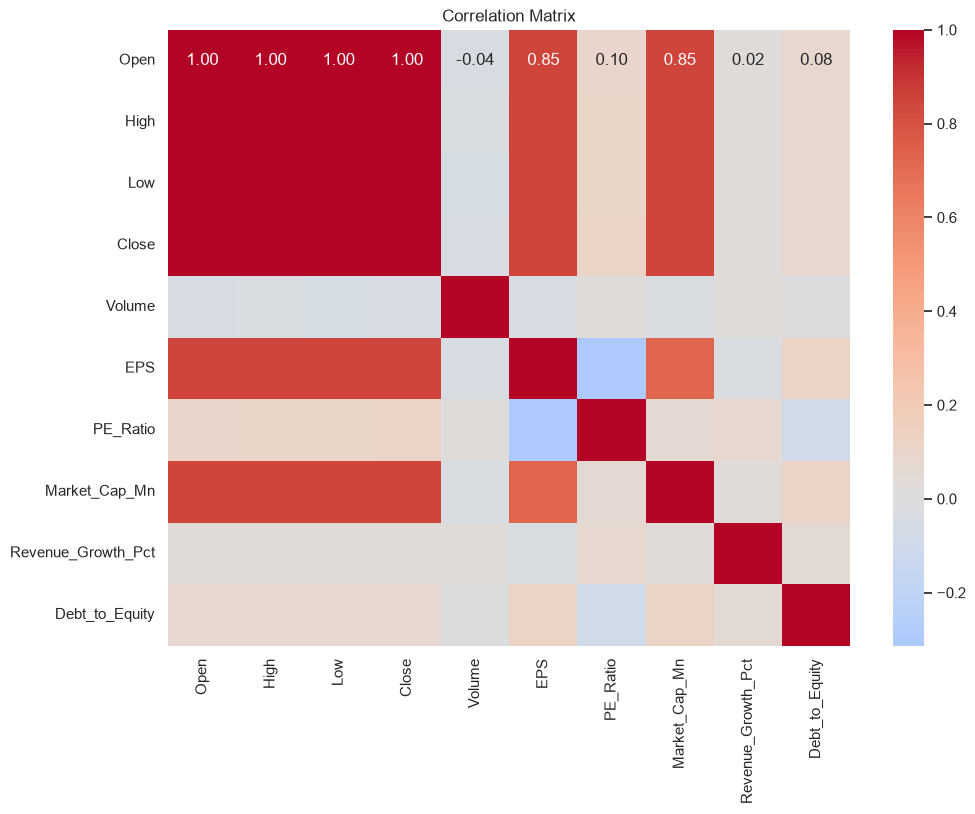

In [16]:
num_cols = ['Open','High','Low','Close','Volume','EPS','PE_Ratio','Market_Cap_Mn','Revenue_Growth_Pct','Debt_to_Equity']
plt.figure(figsize=(11, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

### 4.8 Relationship of Features with Close Price

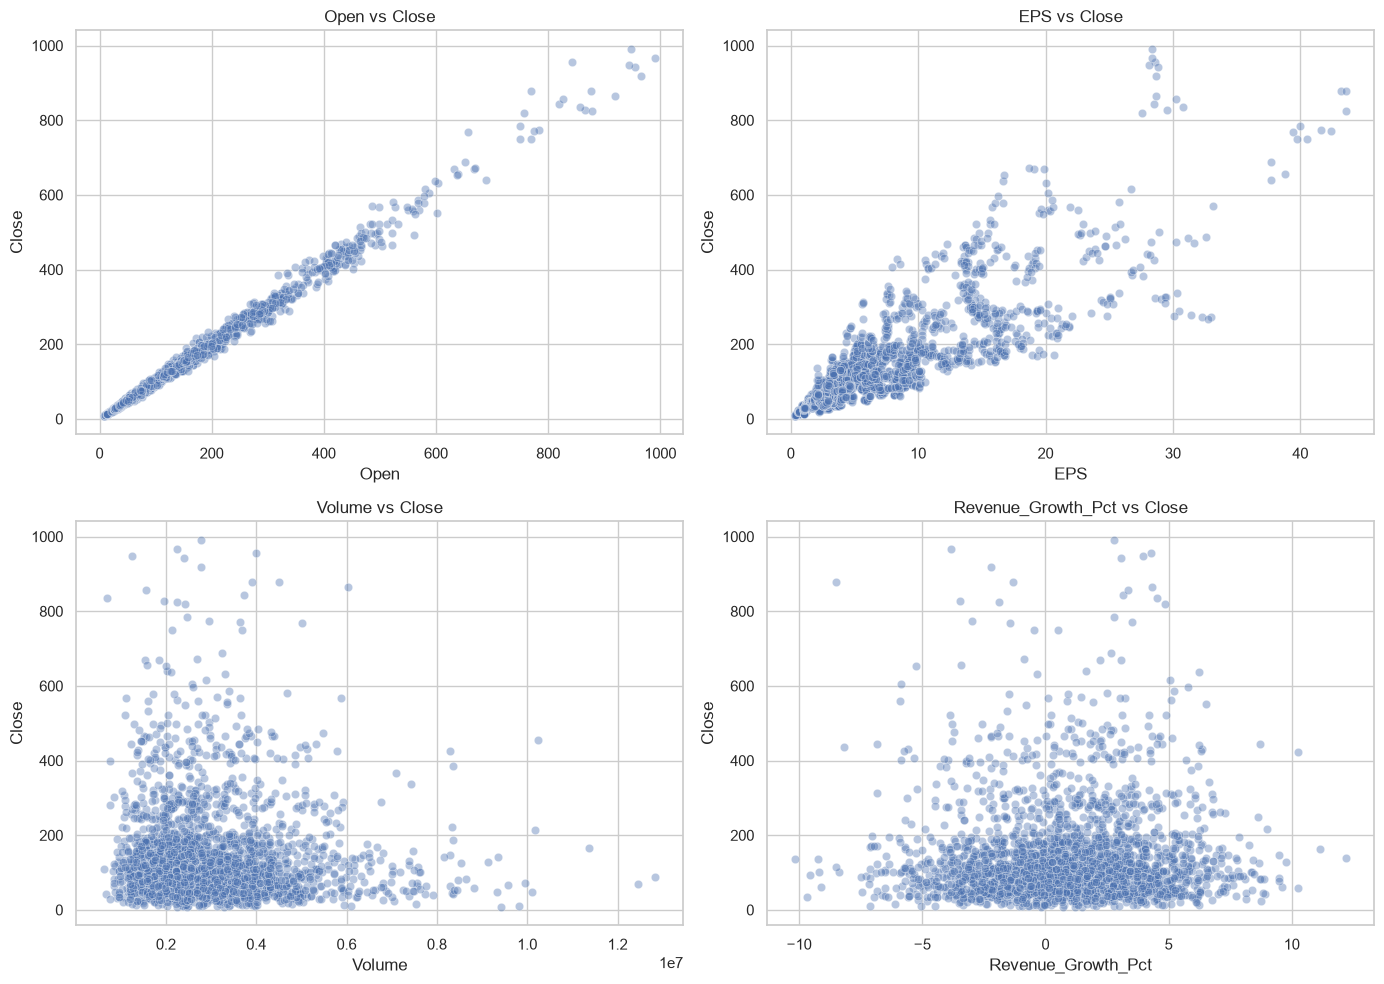

In [17]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
for a, col in zip(ax.ravel(), ['Open','EPS','Volume','Revenue_Growth_Pct']):
    sns.scatterplot(data=df, x=col, y='Close', alpha=0.4, ax=a)
    a.set_title(f'{col} vs Close')
plt.tight_layout(); plt.show()

### 4.9 Volume and Monthly Return

OptionError: No such keys(s): 'mode.use_inf_as_na'

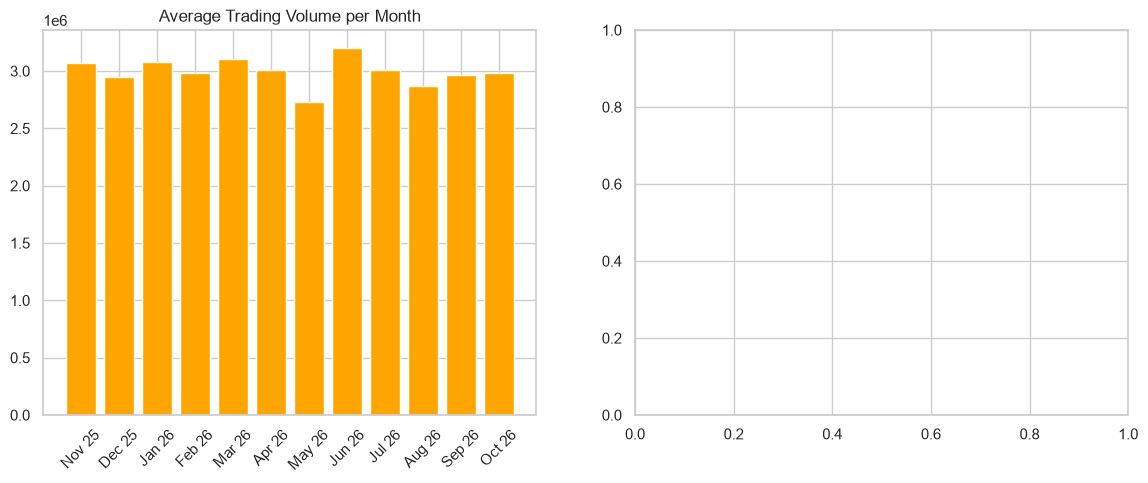

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
vol = df.groupby('Date')['Volume'].mean()
ax[0].bar(vol.index.strftime('%b %y'), vol.values, color='orange')
ax[0].set_title('Average Trading Volume per Month')
ax[0].tick_params(axis='x', rotation=45)
sns.histplot(df['Monthly_Return_Pct'], bins=40, kde=True, color='purple', ax=ax[1])
ax[1].set_title('Monthly Return (%) Distribution')
plt.tight_layout(); plt.show()

### 4.10 Average Monthly Return by Sector

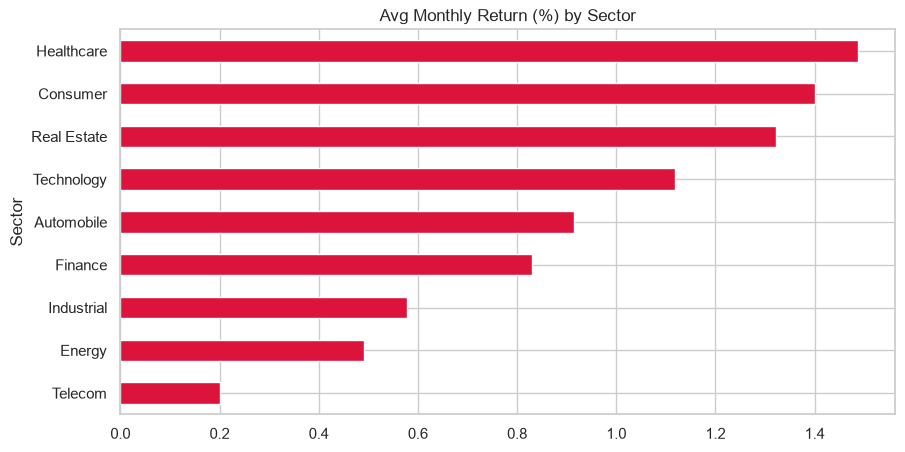

In [19]:
df.groupby('Sector')['Monthly_Return_Pct'].mean().sort_values().plot(kind='barh', color='crimson')
plt.title('Avg Monthly Return (%) by Sector')
plt.show()

## 5. Build the Linear Regression Model
**Target:** `Close`  
**Features:** Open, High, Low, Volume, EPS, Revenue Growth, Debt-to-Equity, Month and Sector (one-hot encoded).  
> `PE_Ratio` and `Market_Cap_Mn` are **excluded** because they are calculated from `Close` (data leakage).  
> A **time-based split** is used: first 10 months for training, last 2 months for testing - just like real forecasting.

In [20]:
features = ['Open','High','Low','Volume','EPS','Revenue_Growth_Pct','Debt_to_Equity','Month']
X = pd.get_dummies(df[features + ['Sector']], columns=['Sector'], drop_first=True)
y = df['Close']

cutoff = pd.Timestamp(df['Date'].sort_values().unique()[-2])          # last 2 months = test
train_idx = df['Date'] < cutoff
X_train, X_test = X[train_idx], X[~train_idx]
y_train, y_test = y[train_idx], y[~train_idx]
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (2000, 16) | Test: (400, 16)


In [21]:
model = LinearRegression()
model.fit(X_train, y_train)
print('Intercept:', round(model.intercept_, 4))
coef = pd.Series(model.coef_, index=X.columns).sort_values()
coef

Intercept: 0.2271


Open                 -9.401364e-01
Sector_Industrial    -5.183057e-03
Sector_Telecom       -1.805260e-03
Sector_Technology    -1.235853e-03
Volume               -2.621971e-08
Sector_Finance        4.556381e-04
Sector_Healthcare     1.448623e-03
Sector_Consumer       1.472381e-03
Sector_Real Estate    1.739839e-03
Debt_to_Equity        2.945744e-03
Sector_Energy         3.773255e-03
Month                 1.045834e-02
Revenue_Growth_Pct    1.320161e-02
EPS                   2.454137e-02
Low                   9.659384e-01
High                  9.704789e-01
dtype: float64

## 6. Model Evaluation

In [22]:
y_pred = model.predict(X_test)
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2   = r2_score(y_test, y_pred)
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

print(f'R² Score : {r2:.4f}')
print(f'MAE      : {mae:.2f}')
print(f'RMSE     : {rmse:.2f}')
print(f'MAPE     : {mape:.2f}%')

R² Score : 0.9997
MAE      : 1.55
RMSE     : 2.58
MAPE     : 1.09%


OptionError: No such keys(s): 'mode.use_inf_as_na'

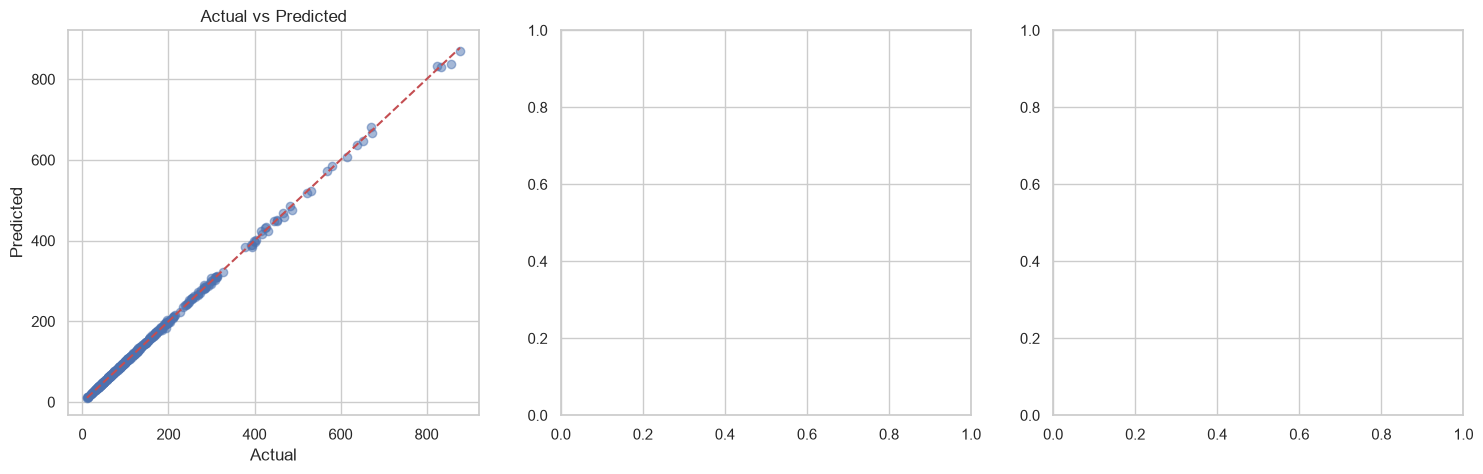

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
# Actual vs Predicted
ax[0].scatter(y_test, y_pred, alpha=0.5)
ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
ax[0].set_title('Actual vs Predicted'); ax[0].set_xlabel('Actual'); ax[0].set_ylabel('Predicted')
# Residual distribution
residuals = y_test - y_pred
sns.histplot(residuals, bins=30, kde=True, ax=ax[1], color='green')
ax[1].set_title('Residual Distribution')
# Residuals vs Predicted
ax[2].scatter(y_pred, residuals, alpha=0.5, color='orange')
ax[2].axhline(0, color='red', linestyle='--')
ax[2].set_title('Residuals vs Predicted'); ax[2].set_xlabel('Predicted'); ax[2].set_ylabel('Residual')
plt.tight_layout(); plt.show()

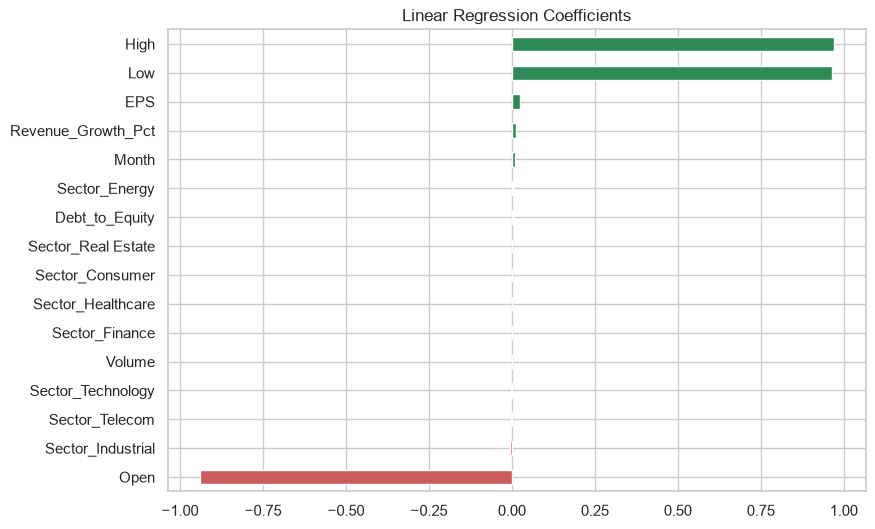

In [24]:
# Feature importance (coefficients)
coef.plot(kind='barh', figsize=(9, 6), color=np.where(coef > 0, 'seagreen', 'indianred'))
plt.title('Linear Regression Coefficients'); plt.show()

## 7. Predictions for a Sample Company

In [25]:
sample_company = 'Apex Technologies' if 'Apex Technologies' in df['Company'].values else df['Company'].iloc[0]
comp = df[df['Company'] == sample_company].copy()
comp_X = pd.get_dummies(comp[features + ['Sector']], columns=['Sector'], drop_first=True)
comp_X = comp_X.reindex(columns=X.columns, fill_value=0)
comp['Predicted_Close'] = model.predict(comp_X).round(2)
comp['Error'] = (comp['Close'] - comp['Predicted_Close']).round(2)
print('Sample company:', sample_company, '| Sector:', comp['Sector'].iloc[0])
comp[['Date','Open','Close','Predicted_Close','Error']].reset_index(drop=True)

Sample company: Alpha Motors | Sector: Automobile


,Date,Open,Close,Predicted_Close,Error
0,2025-11-01,370.11,402.79,401.76,1.03
1,2025-12-01,402.79,373.70,364.87,8.83
2,2026-01-01,373.70,424.89,433.89,-9.00
3,2026-02-01,424.89,414.88,416.30,-1.42
4,2026-03-01,414.88,404.44,401.90,2.54
5,2026-04-01,404.44,404.22,398.91,5.31
6,2026-05-01,404.22,414.37,411.15,3.22
7,2026-06-01,414.37,442.08,436.47,5.61
8,2026-07-01,442.08,436.50,436.13,0.37
9,2026-08-01,436.50,444.44,434.52,9.92


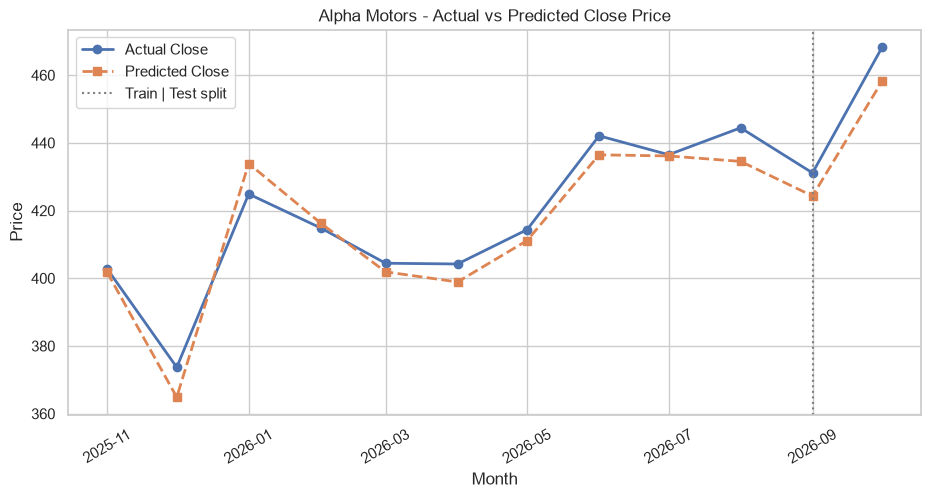

In [26]:
plt.figure(figsize=(11, 5))
plt.plot(comp['Date'], comp['Close'], marker='o', label='Actual Close', linewidth=2)
plt.plot(comp['Date'], comp['Predicted_Close'], marker='s', linestyle='--', label='Predicted Close', linewidth=2)
plt.axvline(cutoff.to_pydatetime(), color='gray', linestyle=':', label='Train | Test split')
plt.title(f'{sample_company} - Actual vs Predicted Close Price')
plt.xlabel('Month'); plt.ylabel('Price'); plt.legend(); plt.xticks(rotation=30)
plt.show()

### Predict for any new input
Change the values below to predict a stock's close price.

In [27]:
new_stock = {
    'Open': 150.0, 'High': 158.0, 'Low': 147.0, 'Volume': 2_500_000,
    'EPS': 6.5, 'Revenue_Growth_Pct': 3.2, 'Debt_to_Equity': 0.8,
    'Month': 11, 'Sector': 'Technology'
}
new_df = pd.get_dummies(pd.DataFrame([new_stock]), columns=['Sector'])
new_df = new_df.reindex(columns=X.columns, fill_value=0)
print(f"Predicted Close Price: {model.predict(new_df)[0]:.2f}")

Predicted Close Price: 154.79


## 8. Conclusion
- Linear Regression predicts the **Close price** well on unseen months (see R², MAE, RMSE, MAPE above).
- **Open, High and Low** prices are the strongest predictors; EPS and sector add smaller effects.
- Residuals are centred around zero, so the linear assumption holds reasonably.
- **Next steps:** try Ridge/Lasso, Random Forest, or lag features to forecast the *next* month's price.